In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.time import Time
from datetime import date

from punchbowl.data.visualize import cmap_punch

from syncom_prams import default_syncom_prams
from syncom_load import syncom_load
from gaussian_function import gaussian_wave
from syncom_image import syncom_image
from syncom_core import syncom_core
from syncom_path import syncom_output_path, syncom_run_dir, syncom_run_name
from syncom_movie import save_syncom_movie, save_rect_movie, plot_rect_image
from polar_to_rect import polar_to_rect


# Parameter Initialization

The <code>default_syncom_prams</code> module sets up the core parameters required to run a SynCOM simulation. It initializes values stored in ModPramsStruct, such as:

<ul>
<li><code>nblobs</code>: Number of synthetic solar wind blobs.</li>
<li><code>nθ</code>, <code>nr</code>: Image resolution in position angle and radial distance (defaults match COR2 resolution).</li>
<li><code>r0</code>: Initial radial launch position of blobs.</li>
</ul>

Optional parameters allow finer control:

<ul>
<li><b>Cadence</b>: Time step between frames (e.g., 300s for COR2 special campaigns).</li>
<li><b>Pixel size</b>: 9.744 Mm (≈0.014 R☉ per pixel in deep-field mode).</li>
<li><b>Acceleration</b>, peak brightness, and noise level: Tunable physical properties.</li>
</ul>

These values are informed by observational constraints, particularly from the COR2 instrument aboard the STEREO spacecraft (Howard et al., 2008; Kaiser et al., 2008).

In [2]:
params = default_syncom_prams(SYNCOM_N_BLOBS=5000,DATE="2023-04-11", SAVEPRAMS="syncom_params.npy")

params

Saved SYNCOM parameters to: syncom_params.npy


{'Name': 'syncom',
 'Label': 'SynCOM model, cube=2023-04-11\nobserver date=2023-04-11',
 'filename': '/Users/valmirmoraesfilho/stereo_analysis.sav',
 'syncom_cadence': 300.0,
 'syncom_pixel': 0.014,
 'syncom_n_blobs': 5000,
 'syncom_acc': 0,
 'syncom_time': 0.0,
 'syncom_nx': 3600,
 'syncom_ny': 659,
 'syncom_initial_R_sun': 5.0,
 'syncom_scale_factor': 2.0,
 'syncom_noise_level': 0.0,
 'syncom_max_intensity': 1e-14,
 'syncomfile': 'syncom_20230411_densfix.sav'}

In [3]:
n_blobs = params["syncom_n_blobs"]
nx = params["syncom_nx"]
ny = params["syncom_ny"]
scale_factor = params["syncom_scale_factor"]
pixel_size = params["syncom_pixel"]
cadence = params["syncom_cadence"]
Rsun2Km = 696000.0
spatial_scale = Rsun2Km * pixel_size

# Loading Profiles

The <code>SYNCOMLOAD</code> module imports the key input profiles needed to simulate each solar wind blob, including:

<ul>
<li><b>Velocity</b>, <b>appearance frequency</b>, and <b>radial position</b></li>
<li><b>Central position angle (θ₀)</b> and <b>initial launch conditions</b></li>
</ul>

Profiles can be loaded from observational datasets or external sources, offering flexibility for different research goals. Blob-specific parameters are stored in LoadStruc, ensuring:

<ul>
<li>Unique <b>velocity</b>, <b>period</b>, <b>radius</b>, and <b>launch coordinates</b> per blob</li>
<li>A realistic, heterogeneous solar wind outflow scenario</li>
</ul>

This data-driven setup enables SynCOM to reflect real-world solar wind variability.

In [4]:
# Load with sinusoidal velocity profile
load_struc = syncom_load(params, simple=True)
outarray = load_struc["outarray"]

# Check shape
print(outarray.shape)

(5000, 8)


In [5]:
time_0 = np.random.default_rng(22).uniform(1.0, 201.0, n_blobs)
radial_i = outarray[:, 0] / pixel_size
period_array = outarray[:, 4]
v_array = (outarray[:, 5] * cadence) / spatial_scale  # pixels/frame
L_array = scale_factor * outarray[:, 6] / 0.1
PSI = outarray[:, 7]    

# Gaussian Function

The GAUSSIANWAVE function generates 1D or 2D Gaussian profiles to model transient solar wind features (blobs) in SynCOM.

## Inputs:
<ul>
<li><code>npixel</code>: Number of pixels

1D: [nx]

2D: [nx, ny]
</li>
<li><code>position</code>: Central position of the Gaussian

1D: [x₀]

2D: [x₀, y₀]
</li>
<li><code>width</code>: Standard deviation (spread)

1D: [σₓ]

2D: [σₓ, σᵧ]
</li>
</ul>

### Description:

Each Gaussian represents the intensity distribution of a blob, allowing precise control over its location and shape within the image. In 2D, the Gaussian evolves along the radial (y) direction to simulate outward-propagating density structures carried by the solar wind.

This function is repeatedly used in <code>syncom_image</code> to generate the dynamic frames of the simulation.




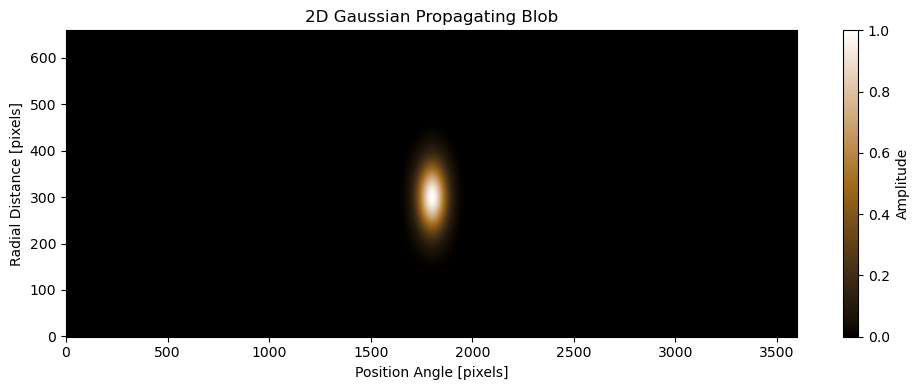

In [6]:
# Parameters for 2D Gaussian blob
npixel = [3600, 659]         # Image dimensions: [position angle, radial distance]
center = [1800, 300]          # Center position of the Gaussian blob
st_dev = [50, 50]            # Standard deviation in each direction

# Generate the 2D Gaussian profile
blob = gaussian_wave(npixel, center, st_dev)

# Plot the result
plt.figure(figsize=(10, 4))
plt.imshow(blob.T, origin='lower', aspect='auto', cmap=cmap_punch)
plt.colorbar(label='Amplitude')
plt.title('2D Gaussian Propagating Blob')
plt.xlabel('Position Angle [pixels]')
plt.ylabel('Radial Distance [pixels]')
plt.tight_layout()
plt.show()

# Image Generation

The SYNCOM_IMAGE module creates 2D synthetic images of the solar wind by summing multiple Gaussian blobs distributed across position angles (θ) and radial distances (r).

## Inputs:
<ul> 
    <li><code>params</code>: Dictionary with simulation settings 
        (<code>syncom_nx</code>, <code>syncom_ny</code>, <code>syncom_n_blobs</code>)</li> 
    <li><code>syncom_version</code>: String label used to name output FITS files</li> 
    <li><code>time_0</code>: Initial time offset in frames</li> 
    <li><code>radial_i</code>: Array of initial radial positions for each blob [pixels]</li> 
    <li><code>v_array</code>: Array of radial velocities [pixels/frame]</li> 
    <li><code>period_array</code>: Array controlling the periodicity of blob reappearance [seconds]</li> 
    <li><code>L_array</code>: Blob width array [degrees], determines radial and angular size</li> 
    <li><code>PSI</code>: Central position angles (θ) for each blob [degrees]</li> 
    <li><code>time_t</code>: Current simulation time step [frames]</li> 
</ul>

### Description:

At each time step, the function computes the radial shift of each blob based on its velocity and time offset. A base 2D Gaussian is generated using gaussian_wave, centered at the blob's specified position and width.

To simulate quasiperiodic structures, harmonic duplicates of each blob are added at fixed intervals along the radial axis. The main Gaussian and its harmonics are then shifted according to the blob's current position.

All blobs are summed into a cumulative 2D array representing the full image of the synthetic solar wind outflow. This image is saved as a FITS file, preserving its resolution and enabling further analysis.

PS: The function is called by <code>SYNCOM_CORE</code> at every timestep from <code>t = 0</code> to <code>t = t_final</code>, capturing both fine- and large-scale transient solar wind dynamics.

In [7]:
# Example parameters (replace with actual simulation values)
syncom_version = 'v1'
time_0 = 499
time_t = 500
scalefactor = 2.0

# Derived physical quantities
radial_i = outarray[:, 0] / pixel_size                         # Convert initial radial position to pixels
v_array = (outarray[:, 5] * cadence) / spatial_scale           # Velocity array in pixels/frame
period_array = outarray[:, 4]                                  # Periods of blob recurrence
# L_array = scale_factor * outarray[:, 6] / 0.1                  # Blob widths scaled
L_array = 4.0 * outarray[:, 6] / 0.1                  # Blob widths scaled
PSI = outarray[:, 7]                                           # Angular positions (θ)

# Generate the synthetic image
img = syncom_image(params, syncom_version, scalefactor, time_0, radial_i,
                   v_array, period_array, L_array, PSI, time_t)


In [8]:
N_BLOBS=2000
scaleFactor=2.0
dia = date.today().isoformat()   # today's date as YYYY-MM-DD
syncom_version = "v1-fix"   # Label for output files
time0, time_t = 0, 300  # Time steps time0 ... time_t-1

In [9]:
RUN_NAME = syncom_run_name(syncom_version, N_BLOBS, scaleFactor)   # prefix of every file of this run
print("Run folder:", syncom_run_dir(RUN_NAME).resolve())

Run folder: /Users/valmirmoraesfilho/Downloads/SynCOM-python-main/SynCOM_runs/SynCOM_v1-fix_N_BLOBS_2000_SCALE_FACTOR_2.0


In [10]:
# Step 1: Load SynCOM parameters
# params = default_syncom_prams(SYNCOM_N_BLOBS=N_BLOBS, DATE=dia,
#                               SAVEPRAMS=syncom_output_path(RUN_NAME, "run", "params.npy"))
params = default_syncom_prams(SYNCOM_N_BLOBS=N_BLOBS, DATE=dia, SYNCOM_PIXEL=0.0141875720451562,
                              SAVEPRAMS=syncom_output_path(RUN_NAME, "run", "params.npy"))

cube = syncom_core(
        N_BLOBS,            # Number of blobs
        time0=time0,             # Starting time index
        time_t=time_t,           # Ending time index (exclusive)
        syncom_version=syncom_version,
        scale_factor=scaleFactor,        # Optional override for blob size scaling
        simple=True,             # Use real (not sinusoidal) velocity profile
        save=True,               # Save the result as .npz
        params=params            # Parameter dictionary
    )

Saved SYNCOM parameters to: SynCOM_runs/SynCOM_v1-fix_N_BLOBS_2000_SCALE_FACTOR_2.0/SynCOM_v1-fix_N_BLOBS_2000_SCALE_FACTOR_2.0_params.npy
✅ Saved: SynCOM_runs/SynCOM_v1-fix_N_BLOBS_2000_SCALE_FACTOR_2.0/cubes/SynCOM_v1-fix_N_BLOBS_2000_SCALE_FACTOR_2.0_cube.npz
⏱️ Total runtime: 117.00460815429688 seconds


In [11]:
START_TIME = Time(f"{dia}T00:00:00", scale="utc")   # UTC time of cube frame 0 (time step time0) - edit as needed

In [12]:
scaleFactor=2.0

# Save the simulated cube as an MP4 movie
save_syncom_movie(
    cube,
    filename=syncom_output_path(RUN_NAME, "movies", "polar_movie.mp4"),
    start_time=START_TIME,
    fps=10,                              # 20 frames -> 4 s video
    cadence=params["syncom_cadence"],   # show elapsed time in the title
    title=RUN_NAME,
    # extent=[0, 360, 0, params["syncom_ny"] * params["syncom_pixel"]],  # physical axes
)

2026-11-07 14:36:47 - matplotlib.animation - INFO: MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x520 -pix_fmt rgba -framerate 10 -loglevel error -i pipe: -vcodec libx264 -pix_fmt yuv420p -vf 'scale=trunc(iw/2)*2:trunc(ih/2)*2' -y SynCOM_runs/SynCOM_v1-fix_N_BLOBS_2000_SCALE_FACTOR_2.0/movies/SynCOM_v1-fix_N_BLOBS_2000_SCALE_FACTOR_2.0_polar_movie.mp4


  50/300 frames (4 s)
  100/300 frames (7 s)
  150/300 frames (10 s)
  200/300 frames (14 s)
  250/300 frames (17 s)
  300/300 frames (20 s)
✅ Saved movie: SynCOM_runs/SynCOM_v1-fix_N_BLOBS_2000_SCALE_FACTOR_2.0/movies/SynCOM_v1-fix_N_BLOBS_2000_SCALE_FACTOR_2.0_polar_movie.mp4 (300 frames at 10 fps)


PosixPath('SynCOM_runs/SynCOM_v1-fix_N_BLOBS_2000_SCALE_FACTOR_2.0/movies/SynCOM_v1-fix_N_BLOBS_2000_SCALE_FACTOR_2.0_polar_movie.mp4')

In [13]:
POLAR_PHI_RANGE = (0.0, 359.9)     # [deg]  PA range of a polar frame      (syncomnoise.pro)
POLAR_RHO_RANGE = (5.0, 14.226)    # [Rsun] radial range of a polar frame  (syncomnoise.pro)

In [14]:
# Polar -> Cartesian for one time step of the cube.
# Use the cube directly: plot_syncom_image() only draws and returns None, so `img = plot_syncom_image(...)` sets img to None.
frame = 100                                   # time step to show (cube runs from time0 = 0)
rect_img = polar_to_rect(cube[:, :, frame], POLAR_PHI_RANGE, POLAR_RHO_RANGE, n=1024)

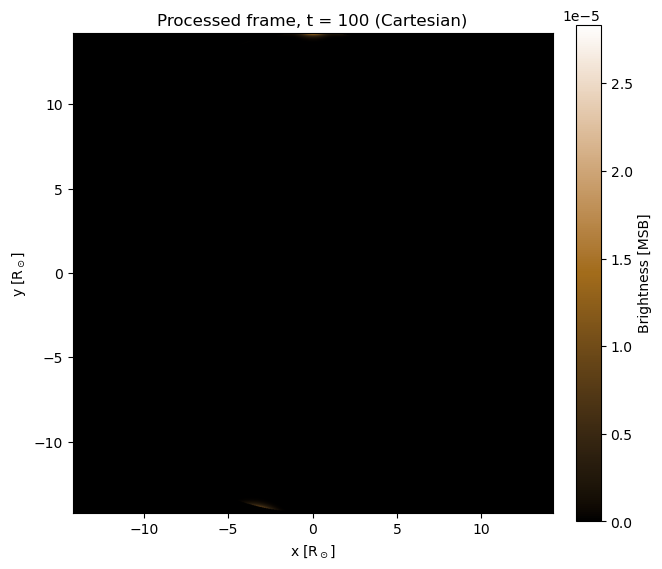

In [15]:
plot_rect_image(rect_img, title=f"Processed frame, t = {frame} (Cartesian)", cmap=cmap_punch,
                label="Brightness [MSB]")

In [16]:
rect_title = f"{RUN_NAME}_rect"
save_rect_movie(
    cube,
    filename=syncom_output_path(RUN_NAME, "movies", "rect_movie.mp4"),
    start_time=START_TIME,
    title=rect_title,
    fps=10,
    # frames=range(0, 100),   # only part of the cube
)

2026-11-07 14:37:07 - matplotlib.animation - INFO: MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x1110 -pix_fmt rgba -framerate 10 -loglevel error -i pipe: -vcodec libx264 -pix_fmt yuv420p -vf 'scale=trunc(iw/2)*2:trunc(ih/2)*2' -y SynCOM_runs/SynCOM_v1-fix_N_BLOBS_2000_SCALE_FACTOR_2.0/movies/SynCOM_v1-fix_N_BLOBS_2000_SCALE_FACTOR_2.0_rect_movie.mp4


  50/300 frames (4 s)
  100/300 frames (9 s)
  150/300 frames (13 s)
  200/300 frames (17 s)
  250/300 frames (21 s)
  300/300 frames (26 s)
✅ Saved movie: SynCOM_runs/SynCOM_v1-fix_N_BLOBS_2000_SCALE_FACTOR_2.0/movies/SynCOM_v1-fix_N_BLOBS_2000_SCALE_FACTOR_2.0_rect_movie.mp4 (300 frames at 10 fps)


PosixPath('SynCOM_runs/SynCOM_v1-fix_N_BLOBS_2000_SCALE_FACTOR_2.0/movies/SynCOM_v1-fix_N_BLOBS_2000_SCALE_FACTOR_2.0_rect_movie.mp4')